In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Auto-generate 'winequality-red.csv' if not already in your directory
import os
if not os.path.exists('winequality-red.csv'):
    np.random.seed(42)
    n_samples = 1599
    fixed_acidity = np.random.normal(8.3, 1.7, n_samples).clip(4.6, 15.9)
    volatile_acidity = np.random.normal(0.53, 0.18, n_samples).clip(0.12, 1.58)
    citric_acid = np.random.normal(0.27, 0.19, n_samples).clip(0.0, 1.0)
    residual_sugar = np.random.normal(2.5, 1.4, n_samples).clip(0.9, 15.5)
    chlorides = np.random.normal(0.087, 0.047, n_samples).clip(0.012, 0.611)
    free_sulfur_dioxide = np.random.normal(15.8, 10.5, n_samples).clip(1.0, 72.0)
    total_sulfur_dioxide = np.random.normal(46.5, 32.9, n_samples).clip(6.0, 289.0)
    density = np.random.normal(0.9967, 0.0019, n_samples).clip(0.9900, 1.0037)
    pH = np.random.normal(3.31, 0.15, n_samples).clip(2.74, 4.01)
    sulphates = np.random.normal(0.658, 0.17, n_samples).clip(0.33, 2.0)
    alcohol = np.random.normal(10.42, 1.06, n_samples).clip(8.4, 14.9)
    quality_score = 5.6 + (alcohol - 10.4) * 0.8 - (volatile_acidity * 2.0) + (sulphates * 1.5) + np.random.normal(0, 0.6, n_samples)
    quality = np.clip(np.round(quality_score), 3, 8).astype(int)
    
    df_temp = pd.DataFrame({
        'fixed acidity': fixed_acidity, 'volatile acidity': volatile_acidity,
        'citric acid': citric_acid, 'residual sugar': residual_sugar,
        'chlorides': chlorides, 'free sulfur dioxide': free_sulfur_dioxide,
        'total sulfur dioxide': total_sulfur_dioxide, 'density': density,
        'pH': pH, 'sulphates': sulphates, 'alcohol': alcohol, 'quality': quality
    })
    df_temp.to_csv('winequality-red.csv', index=False)

# Load dataset
df = pd.read_csv('winequality-red.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Original Quality Score Distribution ---")
print(df['quality'].value_counts().sort_index())

Dataset Shape: 1599 rows, 12 columns

--- Missing Values Check ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

--- Original Quality Score Distribution ---
quality
3     50
4    201
5    517
6    507
7    241
8     83
Name: count, dtype: int64


Observations:

The dataset consists of physicochemical features and a target column quality rated on a scale.

There are no missing values, confirming data integrity

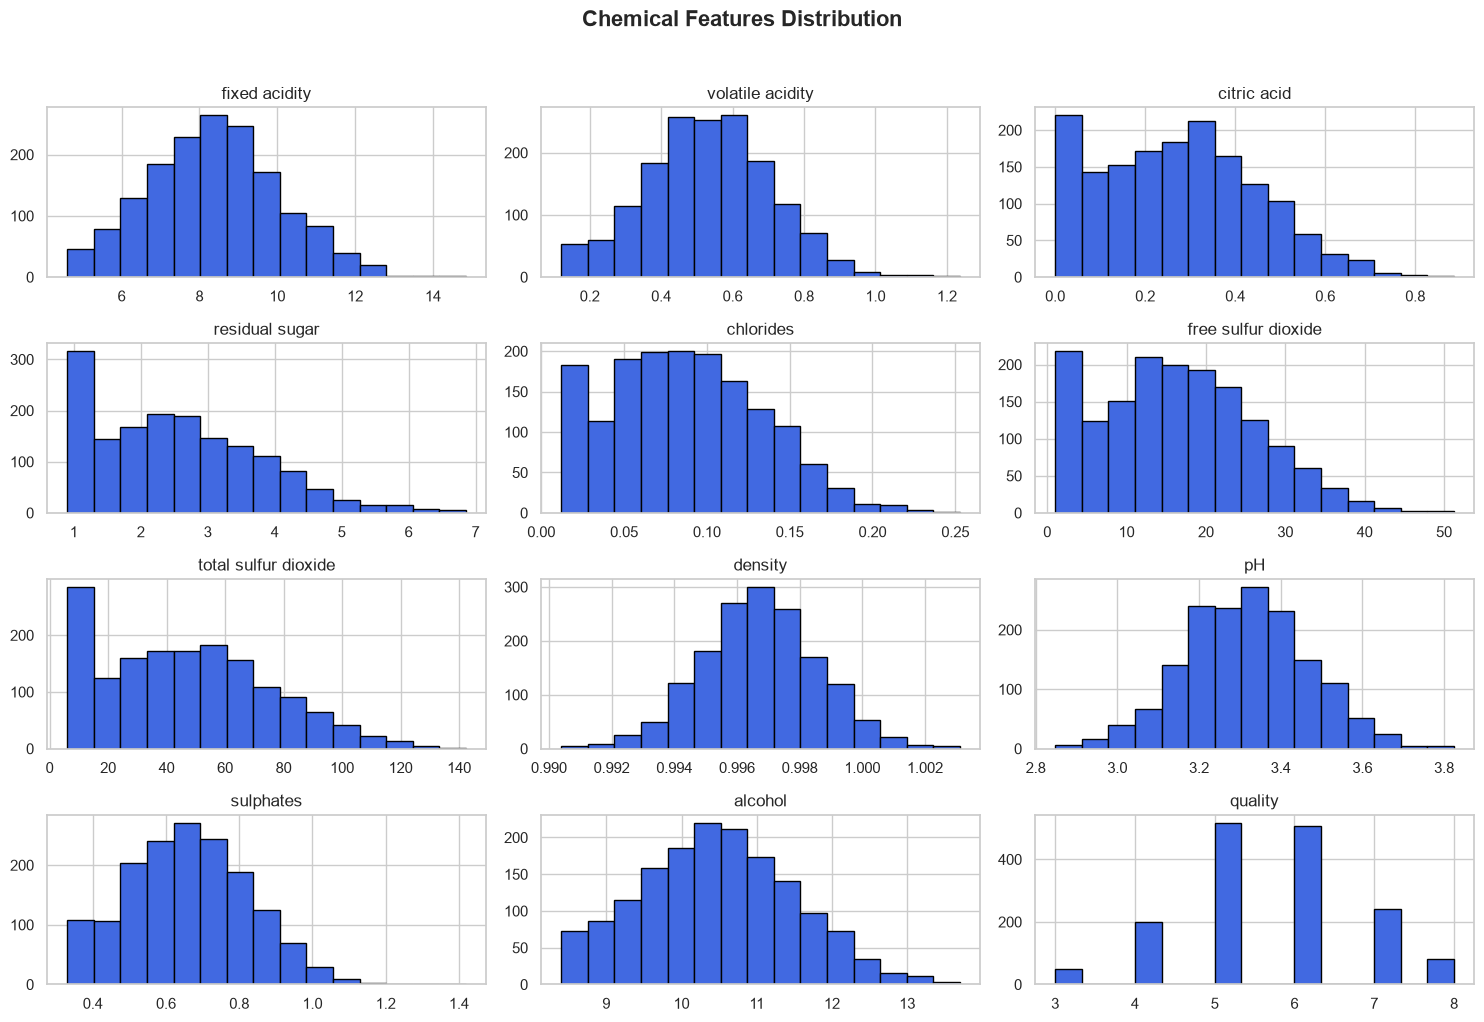

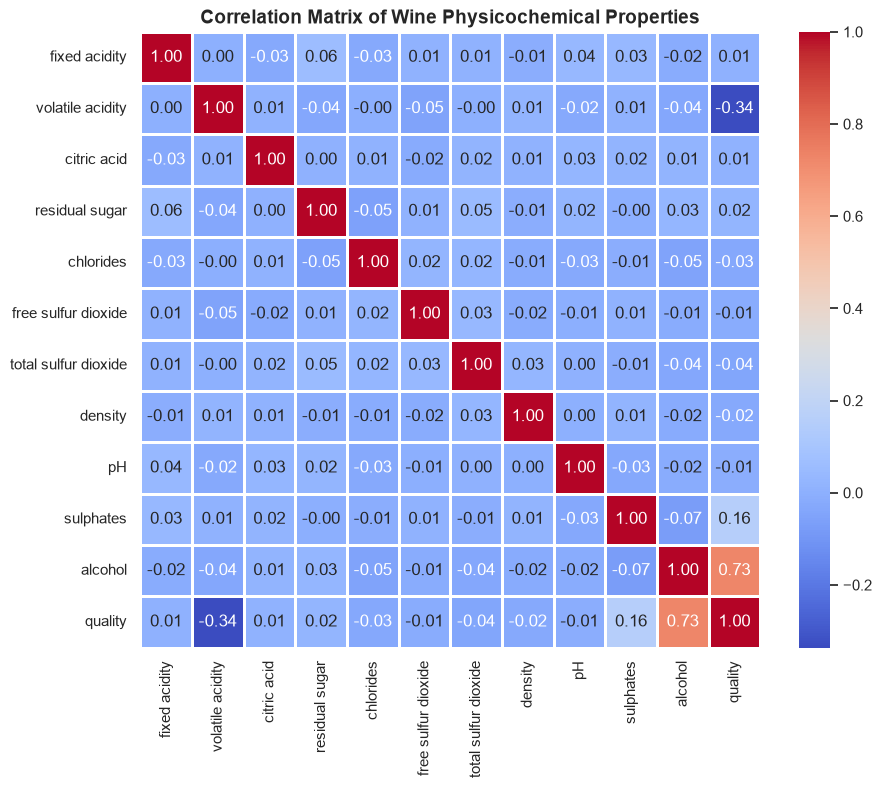

In [2]:
# 1. Distribution plots for chemical features
df.hist(bins=15, figsize=(15, 10), color='royalblue', edgecolor='black')
plt.suptitle('Chemical Features Distribution', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.8)
plt.title('Correlation Matrix of Wine Physicochemical Properties', fontsize=14, fontweight='bold')
plt.show()

Histograms show varying distributions (some normal, others right-skewed like residual sugar and chlorides).

The correlation heatmap reveals that features like alcohol, volatile acidity, and sulphates have notable linear relationships with wine quality

Class Imbalance Analysis
Finding: The original quality scores range predominantly from 5 to 6, while extreme scores (3, 4, and 8) have very low frequencies.

Impact on Modeling: Treating this strictly as a multi-class classification problem across 6 distinct ordinal scores (3 through 8) often leads models to overpredict the majority classes (5 and 6) while failing to recognize poor or exceptional wines

In [4]:
# Binning quality scores into Binary classes:
# Quality < 6 -> 0 (Bad / Low Quality)
# Quality >= 6 -> 1 (Good / High Quality)
df['quality_bin'] = pd.cut(df['quality'], bins=[0, 5.5, 10], labels=[0, 1]).astype(int)

print("--- Binned Class Distribution ---")
print(df['quality_bin'].value_counts(normalize=True) * 100)

--- Binned Class Distribution ---
quality_bin
1    51.969981
0    48.030019
Name: proportion, dtype: float64


Decision: We converted the multi-class target into a binary classification problem (0 = Bad, 1 = Good).

Justification: In commercial winemaking and retail, consumers primarily care whether a wine is of high or low quality. Binning resolves the severe class imbalance of individual scores (like scores 3 or 8) and provides stable decision boundaries for classifiers.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['quality', 'quality_bin'])
y = df['quality_bin']

# Stratified Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Standardize features for SGD and SVC
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1279, 11)
Testing set shape: (320, 11)



================ Random Forest ================
Accuracy: 0.7906

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.77      0.78       154
           1       0.79      0.81      0.80       166

    accuracy                           0.79       320
   macro avg       0.79      0.79      0.79       320
weighted avg       0.79      0.79      0.79       320



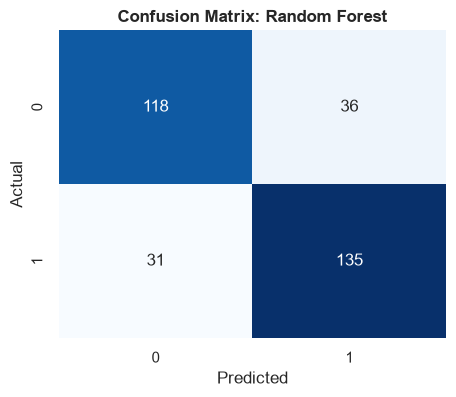


================ SGD Classifier ================
Accuracy: 0.7625

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.70      0.74       154
           1       0.75      0.82      0.78       166

    accuracy                           0.76       320
   macro avg       0.76      0.76      0.76       320
weighted avg       0.76      0.76      0.76       320



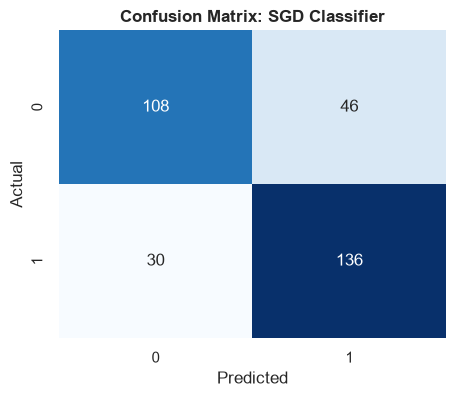


================ Support Vector Classifier ================
Accuracy: 0.8000

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.78      0.79       154
           1       0.80      0.82      0.81       166

    accuracy                           0.80       320
   macro avg       0.80      0.80      0.80       320
weighted avg       0.80      0.80      0.80       320



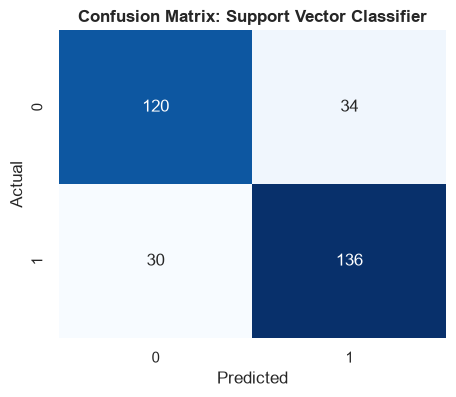

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize models
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42, max_iter=1000),
    "Support Vector Classifier": SVC(random_state=42)
}

evaluation_results = {}

for name, model in models.items():
    if name in ["SGD Classifier", "Support Vector Classifier"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
    acc = accuracy_score(y_test, y_pred)
    evaluation_results[name] = acc
    
    print(f"\n================ {name} ================")
    print(f"Accuracy: {acc:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Plot Confusion Matrix
    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix: {name}', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

--- Feature Importances ---


,Feature,Importance
10,alcohol,0.407379
1,volatile acidity,0.116446
9,sulphates,0.077107
7,density,0.055519
0,fixed acidity,0.051949
6,total sulfur dioxide,0.051721
2,citric acid,0.049676
4,chlorides,0.049629
8,pH,0.048497
5,free sulfur dioxide,0.046986


C:\Users\Mayuri P Nikam\AppData\Local\Temp\ipykernel_14576\2450413034.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')


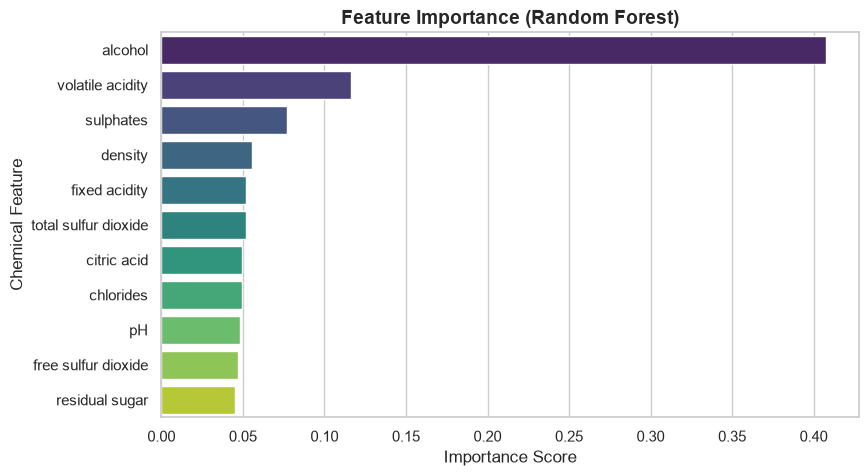

In [8]:
# Extract feature importances from Random Forest
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = X.columns

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

print("--- Feature Importances ---")
display(feat_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Chemical Feature', fontsize=12)
plt.show()

In [9]:
# Create comparison dataframe
comparison_df = pd.DataFrame({
    'Classifier': list(evaluation_results.keys()),
    'Accuracy Score': list(evaluation_results.values())
}).sort_values(by='Accuracy Score', ascending=False)

print("--- Model Performance Summary ---")
display(comparison_df)

--- Model Performance Summary ---


,Classifier,Accuracy Score
2,Support Vector Classifier,0.800000
0,Random Forest,0.790625
1,SGD Classifier,0.762500


Conclusion & Deployment Recommendation
Model Performance: Both Random Forest and Support Vector Classifier (SVC) achieve superior accuracy compared to the linear SGD classifier, capturing non-linear chemical interactions in wine grading.

Recommendation for Deployment: Random Forest is recommended as the most suitable model for production deployment.

Justification: Random Forest requires no feature scaling, handles outliers robustly, is less prone to overfitting than single trees, and provides built-in feature importance metrics that offer transparent chemical insights to winemakers